<a href="https://colab.research.google.com/github/moamenosama1995/My_Portfolio/blob/main/Final_Python_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import pandas as pd
df = pd.read_csv('/content/vgsales.csv')
df = df.sort_values(by='Rank', ascending=True).reset_index(drop=True)
print(df.info())
print(df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
None
   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart W

In [32]:
for col in ['Rank']:
    df[col] = df[col].astype('Int64')

for col in ['Name', 'Platform', 'Genre', 'Publisher', 'Year']:
    df[col] = df[col].astype('string')

print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  Int64  
 1   Name          16598 non-null  string 
 2   Platform      16598 non-null  string 
 3   Year          16327 non-null  string 
 4   Genre         16598 non-null  string 
 5   Publisher     16540 non-null  string 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: Int64(1), float64(5), string(5)
memory usage: 1.4 MB
None
   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wi

In [ ]:
df["Year"].fillna("Unknown", inplace=True)
df["Publisher"].fillna("None", inplace=True)
print(df.isnull().sum())

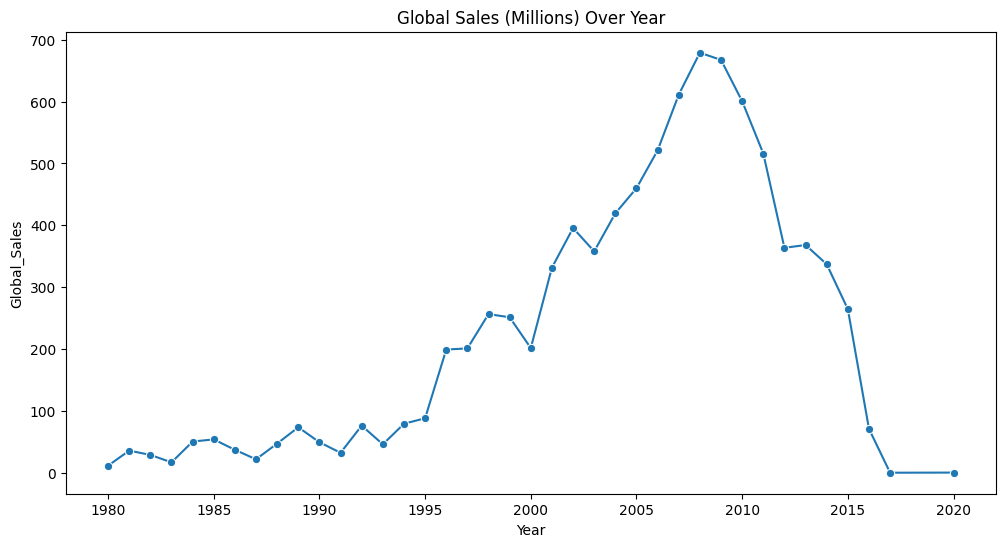

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df.copy()
df_plot['Year'] = pd.to_numeric(df_plot['Year'], errors='coerce')
df_plot = df_plot.dropna(subset=['Year'])
df_plot['Year'] = df_plot['Year'].astype(int)

year_sales = df_plot.groupby('Year')['Global_Sales'].sum().reset_index()

year_sales = year_sales.sort_values(by='Year', ascending=True)


plt.figure(figsize=(12, 6))
sns.lineplot(x='Year', y='Global_Sales', data=year_sales, marker='o')
plt.title('Global Sales (Millions) Over Year')
plt.show()

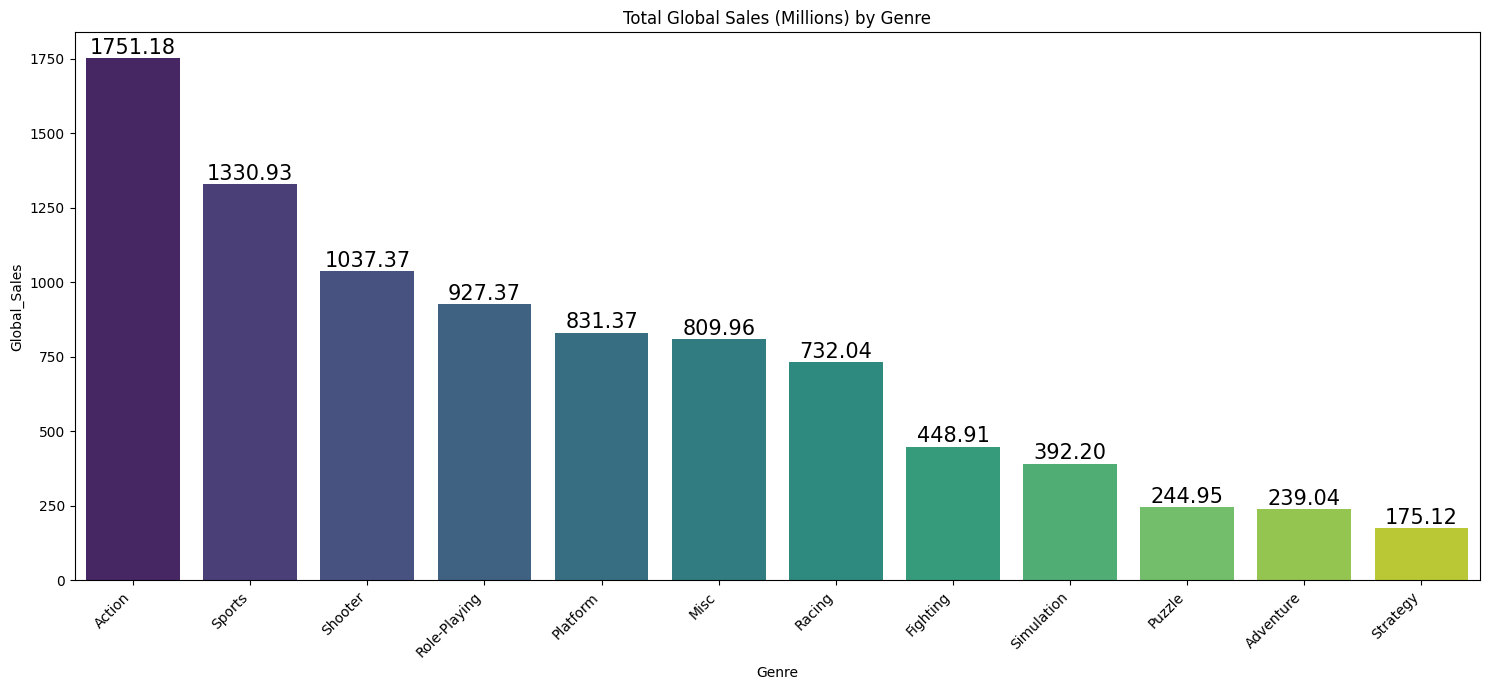

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

genre_sales = df.groupby('Genre')['Global_Sales'].sum().reset_index()

genre_sales = genre_sales.sort_values(by='Global_Sales', ascending=False)

plt.figure(figsize=(15, 7))
ax = sns.barplot(x='Genre', y='Global_Sales', data=genre_sales, palette='viridis', hue='Genre', legend=False)
plt.title('Total Global Sales (Millions) by Genre')
plt.xticks(rotation=45, ha='right')


for container in ax.containers:
    for bar in container:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.2f}', ha='center', va='bottom', fontsize=15, color='black')

plt.tight_layout()
plt.show()

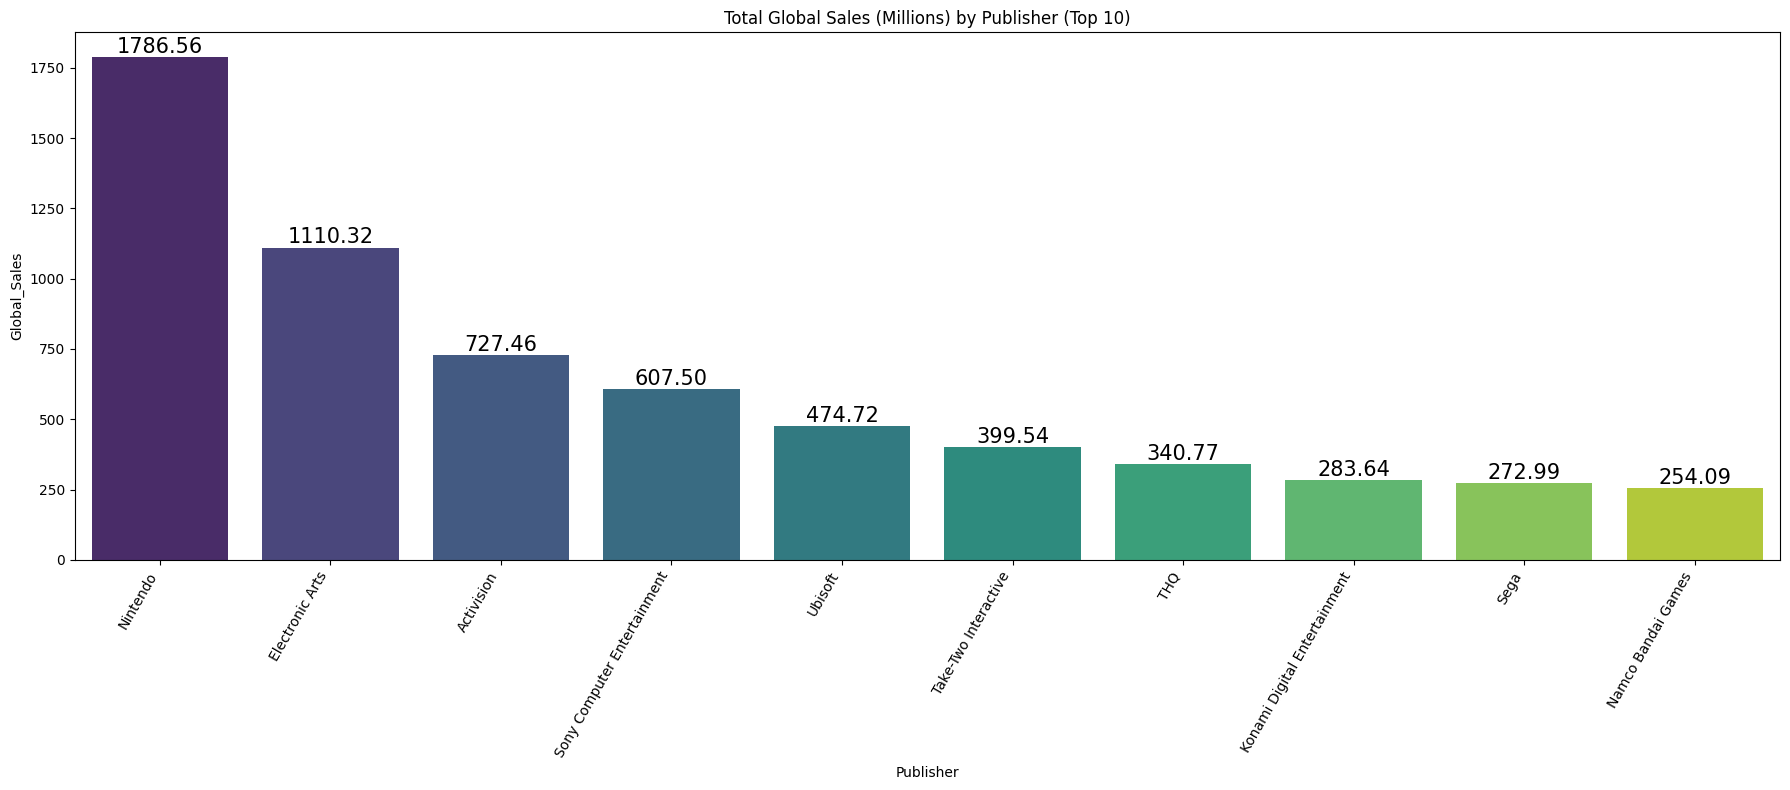

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

publisher_sales = df.groupby('Publisher')['Global_Sales'].sum().reset_index()
publisher_sales = publisher_sales.sort_values(by='Global_Sales', ascending=False)
publisher_sales_top = publisher_sales.head(10)

plt.figure(figsize=(18, 8))
sns.barplot(x='Publisher', y='Global_Sales', data=publisher_sales_top, palette='viridis', hue='Publisher', legend=False)


plt.title('Total Global Sales (Millions) by Publisher (Top 10)')
plt.xticks(rotation=60, ha='right')

ax = plt.gca()
for container in ax.containers:
    for bar in container:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.2f}', ha='center', va='bottom', fontsize=15, color='black')

plt.tight_layout()
plt.show()

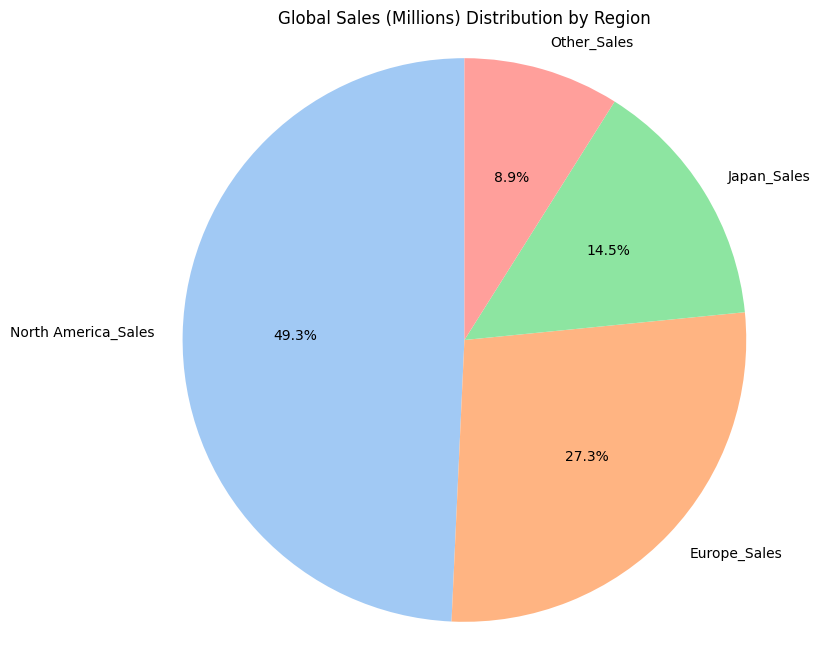

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

na_sales = df['NA_Sales'].sum()
eu_sales = df['EU_Sales'].sum()
jp_sales = df['JP_Sales'].sum()
other_sales = df['Other_Sales'].sum()

sales_values = [na_sales, eu_sales, jp_sales, other_sales]
sales_labels = ['North America_Sales', 'Europe_Sales', 'Japan_Sales', 'Other_Sales']

plt.figure(figsize=(8, 8))
plt.pie(sales_values, labels=sales_labels, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))
plt.title('Global Sales (Millions) Distribution by Region')
plt.axis('equal')
plt.show()

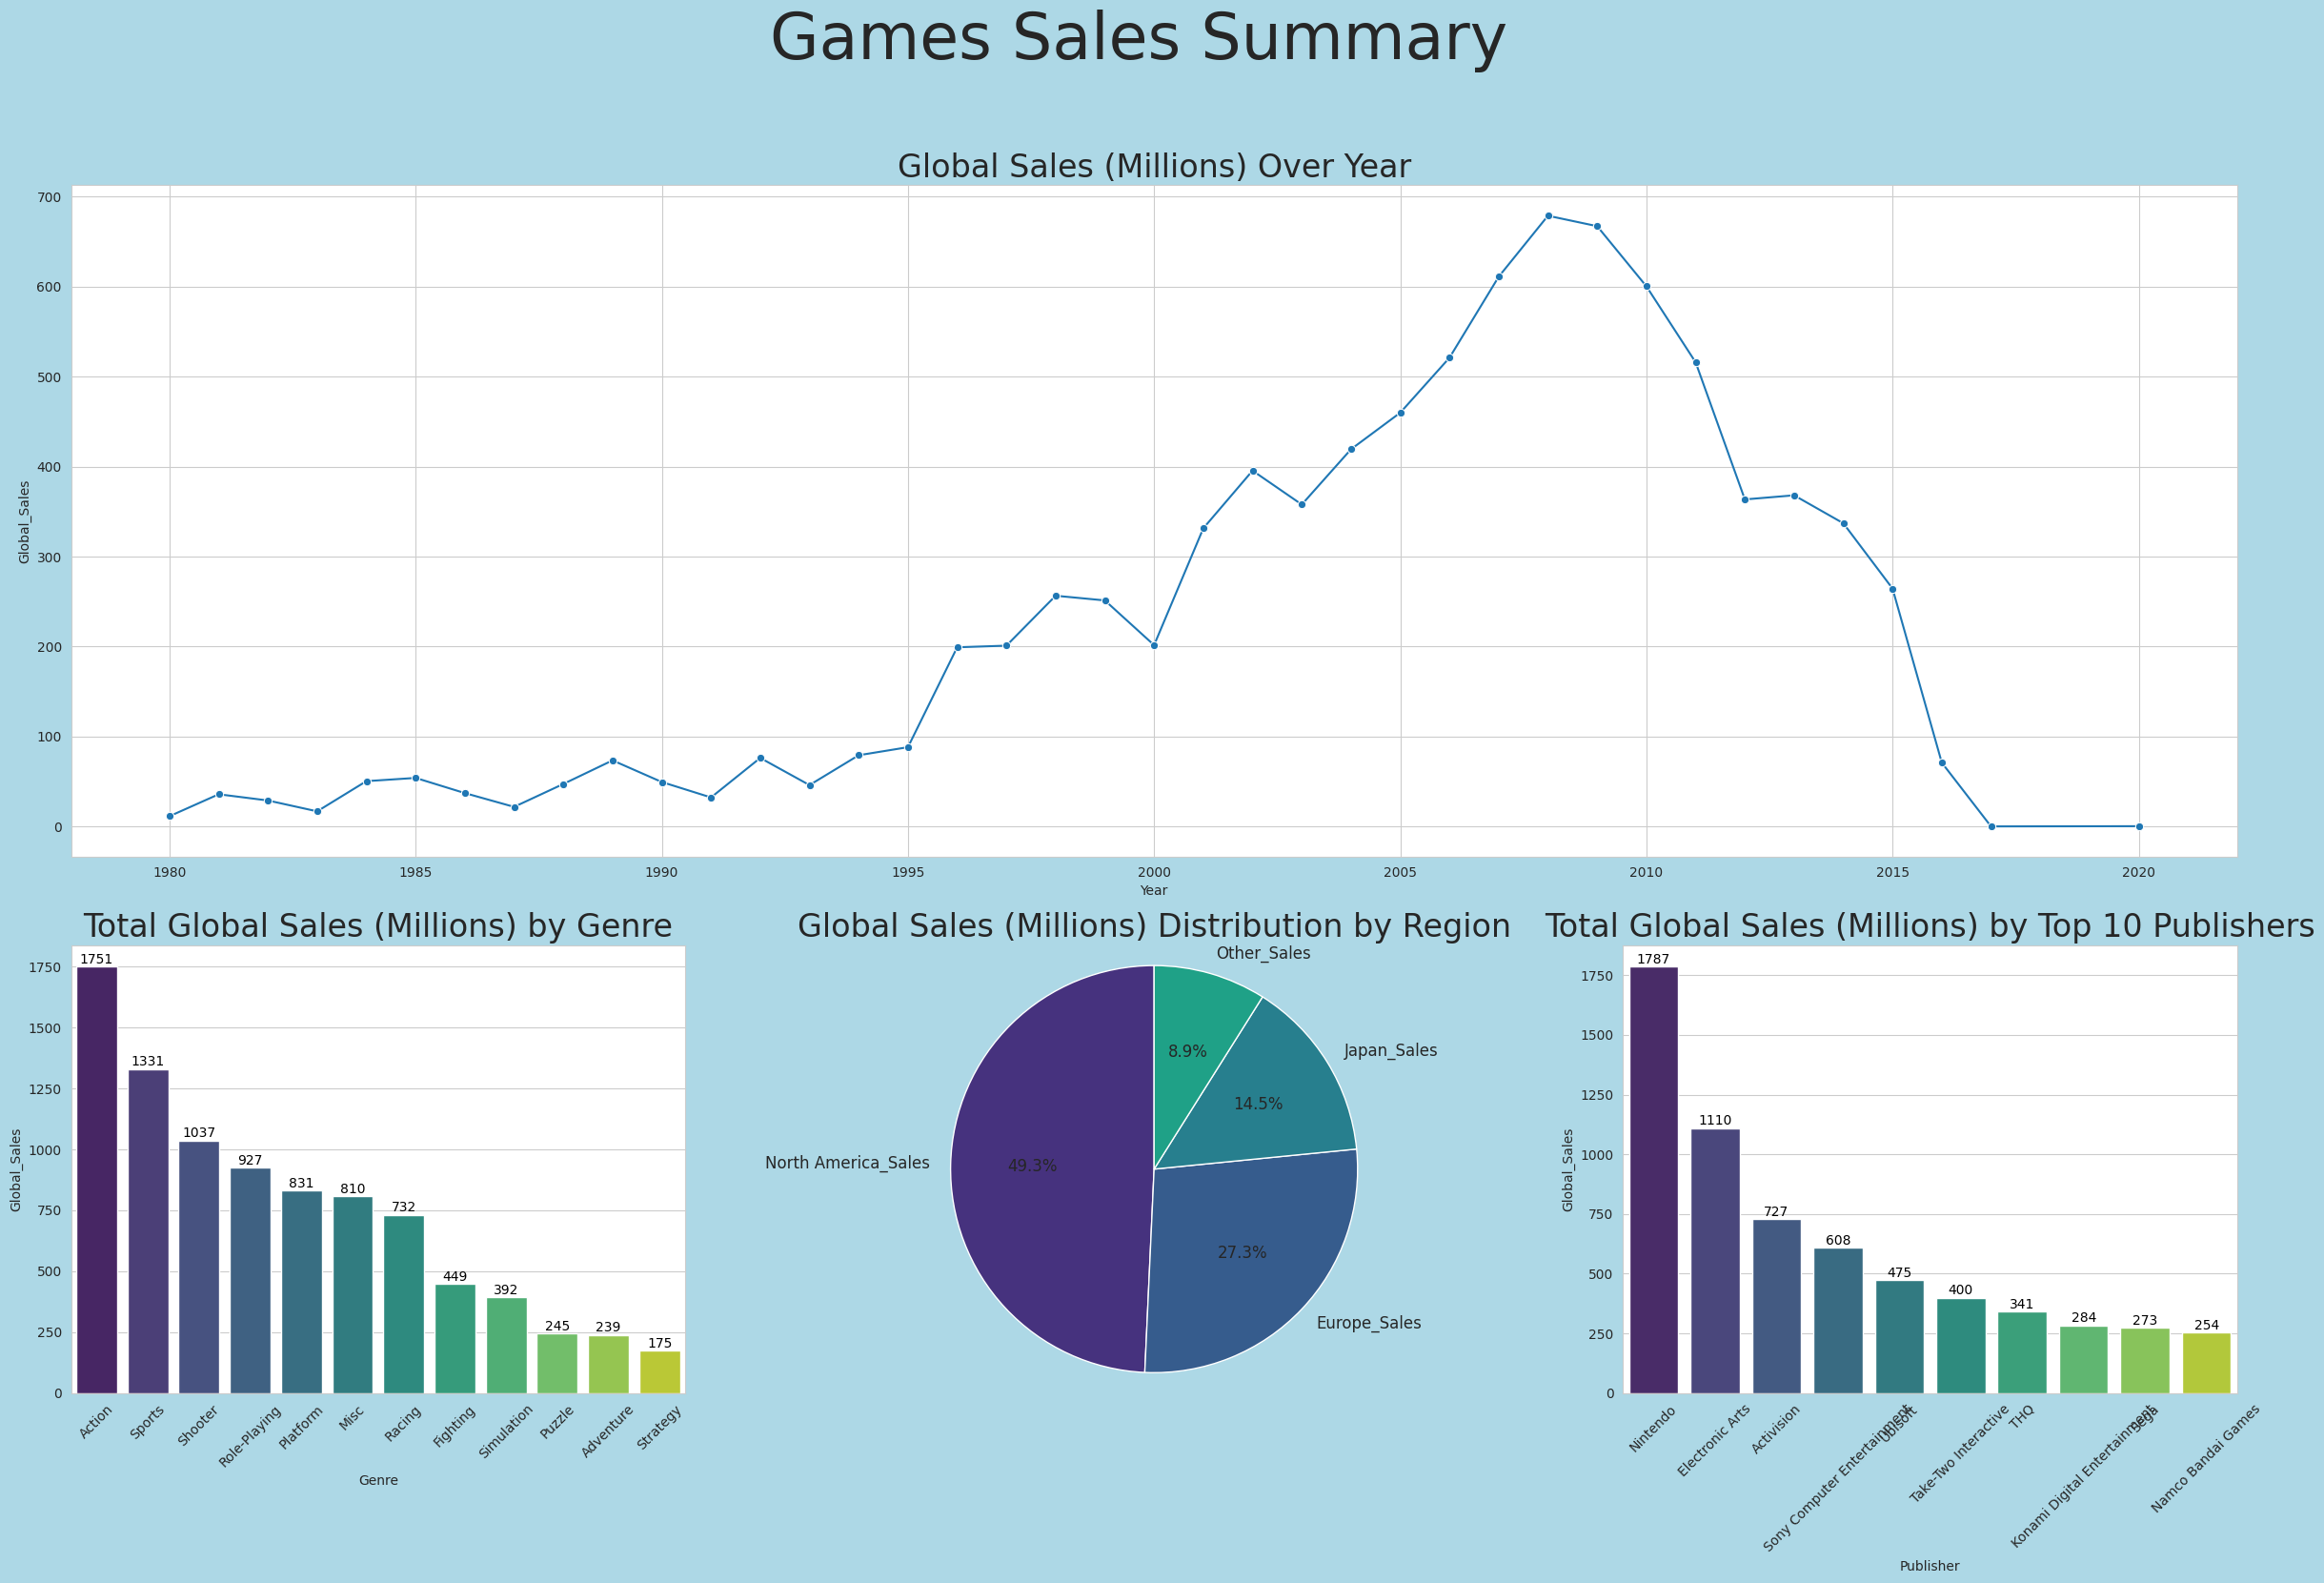

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec

sns.set_style('whitegrid')

df_plot_line = df.copy()
df_plot_line['Year'] = pd.to_numeric(df_plot_line['Year'], errors='coerce')
df_plot_line = df_plot_line.dropna(subset=['Year'])
df_plot_line['Year'] = df_plot_line['Year'].astype(int)

year_sales = df_plot_line.groupby('Year')['Global_Sales'].sum().reset_index()
year_sales = year_sales.sort_values(by='Year', ascending=True)

genre_sales = df.groupby('Genre')['Global_Sales'].sum().reset_index()
genre_sales = genre_sales.sort_values(by='Global_Sales', ascending=False)

na_sales = df['NA_Sales'].sum()
eu_sales = df['EU_Sales'].sum()
jp_sales = df['JP_Sales'].sum()
other_sales = df['Other_Sales'].sum()
sales_values = [na_sales, eu_sales, jp_sales, other_sales]
sales_labels = ['North America_Sales', 'Europe_Sales', 'Japan_Sales', 'Other_Sales']

publisher_sales = df.groupby('Publisher')['Global_Sales'].sum().reset_index()
publisher_sales = publisher_sales.sort_values(by='Global_Sales', ascending=False)
publisher_sales_top = publisher_sales.head(10)

fig = plt.figure(figsize=(24, 18))
fig.set_facecolor('lightblue')
gs = gridspec.GridSpec(2, 3, figure=fig, height_ratios=[1.5, 1])


fig.suptitle('Games Sales Summary', fontsize=48,y=0.95)


ax0 = fig.add_subplot(gs[0, :])
sns.lineplot(x='Year', y='Global_Sales', data=year_sales, marker='o', ax=ax0)
ax0.set_title('Global Sales (Millions) Over Year', fontsize=24)



ax1 = fig.add_subplot(gs[1, 0])
sns.barplot(x='Genre', y='Global_Sales', data=genre_sales, palette='viridis', hue='Genre', legend=False, ax=ax1)
ax1.set_title('Total Global Sales (Millions) by Genre', fontsize=24)
ax1.tick_params(axis='x', rotation=45)
for container in ax1.containers:
    for bar in container:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.0f}', ha='center', va='bottom', fontsize=10, color='black')


ax2 = fig.add_subplot(gs[1, 1])
ax2.pie(sales_values, labels=sales_labels, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("viridis"), textprops={'fontsize': 12}) # Changed color palette here
ax2.set_title('Global Sales (Millions) Distribution by Region', fontsize=24)
ax2.axis('equal')


ax3 = fig.add_subplot(gs[1, 2])
sns.barplot(x='Publisher', y='Global_Sales', data=publisher_sales_top, palette='viridis', hue='Publisher', legend=False, ax=ax3)
ax3.set_title('Total Global Sales (Millions) by Top 10 Publishers', fontsize=24)
ax3.tick_params(axis='x', rotation=45)
for container in ax3.containers:
    for bar in container:
        yval = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.0f}', ha='center', va='bottom', fontsize=10, color='black')


plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()